<a href="https://colab.research.google.com/github/Aditya-Kumar2611/Cognitive-Computing/blob/main/UCS420_LA9_Starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [ ]:
ROLL_NO = 1024170360         # <-- your full roll number
NAME = "Aditya Kumar"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [ ]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [ ]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170360   Name: Aditya Kumar   Fingerprint: 87635BC7   Tickets: 12

Ticket_ID                                                                                   Ticket_Text
      T01                                                   The state-of-the-art lab (Lab-3) is closed.
      T02            VPN keeps asking for login after restarting the system. Is there another solution?
      T03                                The printer keeps asking for login. I don't know what changed.
      T04                                  The e-mail was working yesterday. Is there another solution?
      T05                                                  The email failed to open. Please resolve it.
      T06 I keep getting logged out of the student portal during the lab. It works on another computer.
      T07                                                         The Wi-Fi works, but the VPN doesn't.
      T08                                     The MATLAB stopped responding. I don't

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [ ]:
# Your code
from IPython.display import display
import pandas as pd

# Process every ticket using the original function
processed = {}
rows = []

for row in df.itertuples(index=False):
    result = process_ticket(row.Ticket_Text)
    processed[row.Ticket_ID] = result

    rows.append({
        "Ticket ID": row.Ticket_ID,
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique tokens": len(set(result["tokens"])),
        "Final tokens": len(result["final"])
    })

q1_table = pd.DataFrame(rows)

# Total row: total counts and corpus-wide unique vocabulary
total_row = {
    "Ticket ID": "TOTAL",
    "Sentences": q1_table["Sentences"].sum(),
    "Tokens": q1_table["Tokens"].sum(),
    "Punctuation tokens": q1_table["Punctuation tokens"].sum(),
    "Stopwords": q1_table["Stopwords"].sum(),
    "Unique tokens": len({
        token
        for result in processed.values()
        for token in result["tokens"]
    }),
    "Final tokens": q1_table["Final tokens"].sum()
}

q1_table = pd.concat(
    [q1_table, pd.DataFrame([total_row])],
    ignore_index=True
)

display(q1_table)

# Display actual token lists for one selected ticket
selected_id = FOCUS[0]
selected = processed[selected_id]

selected_text = df.loc[
    df["Ticket_ID"] == selected_id, "Ticket_Text"
].iloc[0]

print("\nSelected ticket:", selected_id)
print("Raw text:", selected_text)
print("Actual tokens:", selected["tokens"])
print("Punctuation tokens:", selected["punct"])
print("Stopwords:", selected["stops"])
print("Final tokens:", selected["final"])

# Observation: contraction fragments that remain in final tokens
fragments = {
    "n't", "'s", "'re", "'ve", "'d", "'ll",
    "'m", "ca", "wo"
}

found_fragments = sorted({
    token
    for result in processed.values()
    for token in result["final"]
    if token in fragments
})

print("\nNon-standard-looking final tokens:", found_fragments)
print("These usually originate from contractions split by word_tokenize().")


,Ticket ID,Sentences,Tokens,Punctuation tokens,Stopwords,Unique tokens,Final tokens
0,T01,1,9,3,2,9,4
1,T02,2,15,2,5,15,8
2,T03,2,14,2,5,13,7
3,T04,2,11,2,4,11,5
4,T05,2,10,2,3,9,5
5,T06,2,19,2,8,17,9
6,T07,1,10,2,4,9,4
7,T08,2,12,2,4,11,6
8,T09,1,5,1,0,5,4
9,T10,1,9,2,2,9,5



Selected ticket: T03
Raw text: The printer keeps asking for login. I don't know what changed.
Actual tokens: ['the', 'printer', 'keeps', 'asking', 'for', 'login', '.', 'i', 'do', "n't", 'know', 'what', 'changed', '.']
Punctuation tokens: ['.', '.']
Stopwords: ['the', 'for', 'i', 'do', 'what']
Final tokens: ['printer', 'keeps', 'asking', 'login', "n't", 'know', 'changed']

Non-standard-looking final tokens: ["n't"]
These usually originate from contractions split by word_tokenize().


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

The only non-standard-looking final token found in my dataset is n't, which appears in ticket T03 from the contraction "don't". It originates from NLTK's word_tokenize() function, which splits contractions into separate tokens. Since the preprocessing pipeline removes stopwords but does not specifically remove contraction fragments, n't remains in the final tokens. These fragments are not meaningful standalone words and can affect the accuracy of further text analysis.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code


import re
from IPython.display import display
import pandas as pd

# Regular expression patterns
patterns = {
    "Words > 5 letters": r"\b[A-Za-z]{6,}\b",
    "Numbers": r"\b\d+(?:[.,]\d+)*\b",
    "Capitalized words": r"\b[A-Z][A-Za-z]*\b",
    "Words starting with vowel": r"\b[aeiou][A-Za-z]*\b"
}

# Patterns for replacing sensitive information
email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"

url_pattern = r"\b(?:https?://|www\.)[^\s<>()]*[A-Za-z0-9/#]\b"

phone_pattern = r"(?<!\w)(?:\+91[\s-]?)?(?:\d{5}[\s-]\d{5}|\d{4}[\s-]\d{3}[\s-]\d{4})(?!\w)"

def extract_features(text):
    return {
        name: re.findall(pattern, text)
        for name, pattern in patterns.items()
    }

def clean_text(text):
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text

# Apply extraction and replacement to all raw tickets
q2_rows = []

for row in df.itertuples(index=False):
    text = row.Ticket_Text
    features = extract_features(text)

    q2_rows.append({
        "Ticket ID": row.Ticket_ID,
        **features,
        "Cleaned Text": clean_text(text)
    })

q2_table = pd.DataFrame(q2_rows)

print("Q2: REGEX EXTRACTION ON GENERATED TICKETS")
display(q2_table)

# Test the patterns on the given TEST_LINES
test_rows = []

for i, text in enumerate(TEST_LINES, start=1):
    features = extract_features(text)

    test_rows.append({
        "Test Line": f"TEST {i}",
        **features,
        "Original Text": text,
        "Cleaned Text": clean_text(text)
    })

test_table = pd.DataFrame(test_rows)

print("\nREGEX VALIDATION ON TEST_LINES")
display(test_table)


Q2: REGEX EXTRACTION ON GENERATED TICKETS


,Ticket ID,Words > 5 letters,Numbers,Capitalized words,Words starting with vowel,Cleaned Text
0,T01,[closed],[3],"[The, Lab]","[of, art, is]",The state-of-the-art lab (Lab-3) is closed.
1,T02,"[asking, restarting, system, another, solution]",[],"[VPN, Is]","[asking, after, another]",VPN keeps asking for login after restarting th...
2,T03,"[printer, asking, changed]",[],"[The, I]",[asking],The printer keeps asking for login. I don't kn...
3,T04,"[working, yesterday, another, solution]",[],"[The, Is]","[e, another]",The e-mail was working yesterday. Is there ano...
4,T05,"[failed, Please, resolve]",[],"[The, Please]","[email, open, it]",The email failed to open. Please resolve it.
5,T06,"[getting, logged, student, portal, during, ano...",[],"[I, It]","[out, of, on, another]",I keep getting logged out of the student porta...
6,T07,[],[],"[The, Wi, Fi, VPN]",[],"The Wi-Fi works, but the VPN doesn't."
7,T08,"[MATLAB, stopped, responding, changed]",[],"[The, MATLAB, I]",[],The MATLAB stopped responding. I don't know wh...
8,T09,[appears],[],[Error],[appears],Error code 0x80070005 appears.
9,T10,"[helpdesk, thapar, thapar]",[],[Write],"[it, edu, or, edu, it]",Write to <EMAIL> or visit <URL>.



REGEX VALIDATION ON TEST_LINES


,Test Line,Words > 5 letters,Numbers,Capitalized words,Words starting with vowel,Original Text,Cleaned Text
0,TEST 1,"[helpdesk, thapar, thapar, thapar]",[],[Mail],"[it, edu, or, a, univ, ac, in, edu, or, edu, it]",Mail it.helpdesk@thapar.edu or a.b-c@dept.univ...,Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>.
1,TEST 2,[Version],"[91, 98765, 43210, 91, 98765, 43210, 0175, 239...","[Call, Version, Rs]","[or, is]","Call +91 98765 43210, +91-98765-43210 or 0175-...","Call <PHONE>, <PHONE> or <PHONE>. Version 2.0...."
2,TEST 3,[],[5.30],[The],"[of, art, isn, open, in, at]",The state-of-the-art lab isn't open; log-in at...,The state-of-the-art lab isn't open; log-in at...


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

Several capitalized words in my dataset are capitalized only because they appear at the beginning of a sentence. For example, The, I, VPN, Wi-Fi, MATLAB, Error, and Write. However, some words are naturally capitalized names or technical terms, such as Python and MATLAB. Therefore, not every capitalized word represents a proper noun; some are capitalized simply due to sentence position.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:

from nltk.tokenize import RegexpTokenizer, word_tokenize
import pandas as pd

# One regex pattern covering URLs, emails, phone numbers,
# decimals/versions, contractions, hyphenated words and normal words.

pattern = r"""(?i)(?:https?://[^\s<>()]+|www\.[^\s<>()]+|[A-Z0-9._%+-]+@[A-Z0-9.-]+\.[A-Z]{2,}|\+91[\s-]?\d{5}[\s-]?\d{5}|\d{4}[- ]\d{3}[- ]\d{4}|\d{5}[- ]\d{5}|\d+(?:[.,]\d+)+|[A-Z]+(?:['’][A-Z]+)+|[A-Z]+(?:-[A-Z]+)+|[A-Z]+)"""

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)


# Run custom tokenizer and word_tokenize on TEST_LINES
test_results = []

for i, text in enumerate(TEST_LINES, start=1):
    test_results.append({
        "Test Line": f"TEST {i}",
        "Original Text": text,
        "Custom Tokens": my_tokenize(text),
        "word_tokenize Tokens": word_tokenize(text)
    })

test_comparison = pd.DataFrame(test_results)

print("CUSTOM TOKENIZER VS NLTK ON TEST_LINES")
display(test_comparison)


# Run both tokenizers on generated tickets
ticket_results = []

for row in df.itertuples(index=False):
    custom = my_tokenize(row.Ticket_Text)
    nltk_tokens = word_tokenize(row.Ticket_Text)

    ticket_results.append({
        "Ticket ID": row.Ticket_ID,
        "Custom Tokens": custom,
        "Custom Token Count": len(custom),
        "word_tokenize Tokens": nltk_tokens,
        "NLTK Token Count": len(nltk_tokens)
    })

ticket_comparison = pd.DataFrame(ticket_results)

print("\nCUSTOM TOKENIZER VS NLTK ON GENERATED TICKETS")
display(ticket_comparison)


# Overall comparison
print("\nOVERALL TOKEN COUNT")

print("Custom tokenizer:",
      ticket_comparison["Custom Token Count"].sum())

print("NLTK word_tokenize:",
      ticket_comparison["NLTK Token Count"].sum())


CUSTOM TOKENIZER VS NLTK ON TEST_LINES


,Test Line,Original Text,Custom Tokens,word_tokenize Tokens
0,TEST 1,Mail it.helpdesk@thapar.edu or a.b-c@dept.univ...,"[Mail, it.helpdesk@thapar.edu, or, a.b-c@dept....","[Mail, it.helpdesk, @, thapar.edu, or, a.b-c, ..."
1,TEST 2,"Call +91 98765 43210, +91-98765-43210 or 0175-...","[Call, +91 98765 43210, +91-98765-43210, or, 0...","[Call, +91, 98765, 43210, ,, +91-98765-43210, ..."
2,TEST 3,The state-of-the-art lab isn't open; log-in at...,"[The, state-of-the-art, lab, isn't, open, log-...","[The, state-of-the-art, lab, is, n't, open, ;,..."



CUSTOM TOKENIZER VS NLTK ON GENERATED TICKETS


,Ticket ID,Custom Tokens,Custom Token Count,word_tokenize Tokens,NLTK Token Count
0,T01,"[The, state-of-the-art, lab, Lab, is, closed]",6,"[The, state-of-the-art, lab, (, Lab-3, ), is, ...",9
1,T02,"[VPN, keeps, asking, for, login, after, restar...",13,"[VPN, keeps, asking, for, login, after, restar...",15
2,T03,"[The, printer, keeps, asking, for, login, I, d...",11,"[The, printer, keeps, asking, for, login, ., I...",14
3,T04,"[The, e-mail, was, working, yesterday, Is, the...",9,"[The, e-mail, was, working, yesterday, ., Is, ...",11
4,T05,"[The, email, failed, to, open, Please, resolve...",8,"[The, email, failed, to, open, ., Please, reso...",10
5,T06,"[I, keep, getting, logged, out, of, the, stude...",17,"[I, keep, getting, logged, out, of, the, stude...",19
6,T07,"[The, Wi-Fi, works, but, the, VPN, doesn't]",7,"[The, Wi-Fi, works, ,, but, the, VPN, does, n'...",10
7,T08,"[The, MATLAB, stopped, responding, I, don't, k...",9,"[The, MATLAB, stopped, responding, ., I, do, n...",12
8,T09,"[Error, code, x, appears]",4,"[Error, code, 0x80070005, appears, .]",5
9,T10,"[Write, to, it.helpdesk@thapar.edu, or, visit,...",6,"[Write, to, it.helpdesk, @, thapar.edu, or, vi...",9



OVERALL TOKEN COUNT
Custom tokenizer: 114
NLTK word_tokenize: 143


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

All 12 tickets are tokenized differently by my_tokenize() and NLTK's word_tokenize(), because the custom tokenizer keeps contractions, hyphenated words, numbers and other structured patterns together, whereas word_tokenize() often splits them into multiple tokens.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:
# Your code


from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet
import pandas as pd

# Collect unique final tokens from all tickets
unique_words = sorted({
    token
    for result in processed.values()
    for token in result["final"]
})

print("Total unique final tokens:", len(unique_words))
print("Unique words:", unique_words)


# Initialize stemmers and lemmatizer
porter = PorterStemmer()
lancaster = LancasterStemmer()

# Chosen suffix rule after inspecting the ticket vocabulary
regex_stemmer = RegexpStemmer(r"(ing|ed|es|s)$")

lemmatizer = WordNetLemmatizer()


# Convert Penn Treebank POS tags to WordNet POS tags
def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN


# POS tagging
tagged_words = pos_tag(unique_words)

# Compare all four methods
comparison = []

for word, tag in tagged_words:
    wn_pos = get_wordnet_pos(tag)

    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regex_result = regex_stemmer.stem(word)
    lemma_result = lemmatizer.lemmatize(word, pos=wn_pos)

    comparison.append({
        "Original Word": word,
        "POS Tag": tag,
        "Porter Stem": porter_result,
        "Lancaster Stem": lancaster_result,
        "Regexp Stem": regex_result,
        "WordNet Lemma": lemma_result
    })


# Create comparison table
q4_table = pd.DataFrame(comparison)

# Keep only rows where at least two methods differ
output_columns = [
    "Porter Stem",
    "Lancaster Stem",
    "Regexp Stem",
    "WordNet Lemma"
]

different_words = q4_table[
    q4_table[output_columns].nunique(axis=1) > 1
]

print("\nWORDS WITH DIFFERENT STEMMING/LEMMATIZATION OUTPUTS:")
display(different_words.reset_index(drop=True))

print("\nTotal unique words:", len(unique_words))
print("Words with differing outputs:", len(different_words))


Total unique final tokens: 52
Unique words: ['0x80070005', 'access', 'another', 'appears', 'asking', 'assignment', 'changed', 'closed', 'code', 'computer', 'deadline', 'e-mail', 'email', 'error', 'failed', 'getting', 'it.helpdesk', 'keep', 'keeps', 'know', 'lab', 'lab-3', 'logged', 'login', 'matlab', "n't", 'open', 'please', 'portal', 'printer', 'resolve', 'responding', 'restarting', 'server', 'since', 'solution', 'state-of-the-art', 'stopped', 'student', 'system', 'thapar.edu', 'unable', 'urgent', 'use', 'visit', 'vpn', 'wi-fi', 'working', 'works', 'write', 'www.thapar.edu/it', 'yesterday']

WORDS WITH DIFFERENT STEMMING/LEMMATIZATION OUTPUTS:


,Original Word,POS Tag,Porter Stem,Lancaster Stem,Regexp Stem,WordNet Lemma
0,access,NN,access,access,acces,access
1,another,DT,anoth,anoth,another,another
2,assignment,NN,assign,assign,assignment,assignment
3,changed,VBD,chang,chang,chang,change
4,closed,JJ,close,clos,clos,closed
5,code,NN,code,cod,code,code
6,computer,NN,comput,comput,computer,computer
7,deadline,NN,deadlin,deadlin,deadline,deadline
8,error,NN,error,er,error,error
9,getting,VBG,get,get,gett,get



Total unique words: 52
Words with differing outputs: 26


**Observe:** Give one over-stemming and one under-stemming example from your table.

- Over-stemming: The word "error" becomes "er" with LancasterStemmer. This is over-stemming because it removes too much of the original word and produces an invalid stem.

- Under-stemming: The word "access" remains "access" with PorterStemmer, even though the RegexpStemmer reduces it to "acces". This demonstrates under-stemming in the sense that PorterStemmer does not remove the suffix that the custom rule targets.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

CORPUS STATISTICS


,Total Tokens,Unique Tokens,TTR
S1 (All tokens),143.0,81.0,0.5664
S2 (No punctuation),119.0,75.0,0.6303
S3 (Final tokens),69.0,52.0,0.7536
S4 (Porter stemmed),69.0,50.0,0.7246



TOP 10 WORDS IN S1


,Word,Frequency
0,.,18
1,the,13
2,i,5
3,is,4
4,another,3
5,n't,3
6,to,3
7,it,3
8,lab,2
9,vpn,2



TOP 10 WORDS IN S3


,Word,Frequency
0,another,3
1,n't,3
2,lab,2
3,vpn,2
4,keeps,2
5,asking,2
6,login,2
7,solution,2
8,know,2
9,changed,2


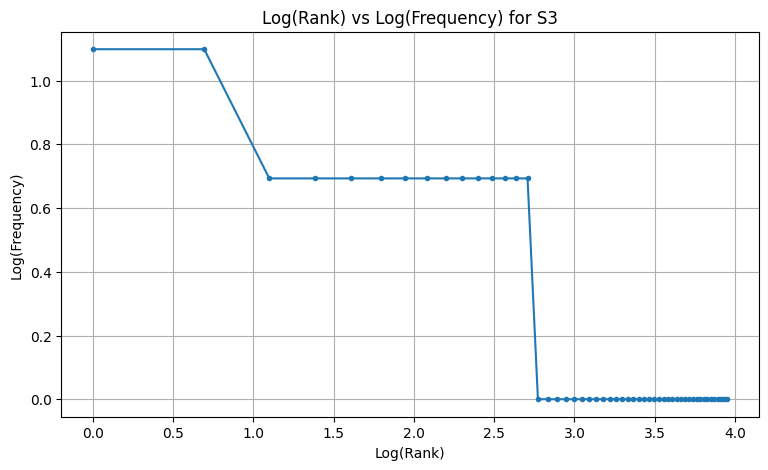


TOP 5 BIGRAMS IN S1


,Bigram,Frequency
0,. i,5
1,. the,3
2,keeps asking,2
3,asking for,2
4,for login,2



TOP 5 BIGRAMS IN S3


,Bigram,Frequency
0,keeps asking,2
1,asking login,2
2,another solution,2
3,n't know,2
4,know changed,2


In [ ]:
# Your code


from collections import Counter
from nltk.stem import PorterStemmer
from nltk.util import bigrams
import matplotlib.pyplot as plt
import pandas as pd
import math

# S1: All tokens
S1 = [
    token
    for result in processed.values()
    for token in result["tokens"]
]

# S2: Tokens without punctuation
S2 = [
    token
    for result in processed.values()
    for token in result["tokens"]
    if not is_punct(token)
]

# S3: Final tokens (without punctuation and stopwords)
S3 = [
    token
    for result in processed.values()
    for token in result["final"]
]

# S4: Porter-stemmed S3
porter = PorterStemmer()
S4 = [porter.stem(token) for token in S3]


# Calculate corpus statistics
def corpus_stats(tokens):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total else 0

    return {
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    }


stats = pd.DataFrame({
    "S1 (All tokens)": corpus_stats(S1),
    "S2 (No punctuation)": corpus_stats(S2),
    "S3 (Final tokens)": corpus_stats(S3),
    "S4 (Porter stemmed)": corpus_stats(S4)
}).T

print("CORPUS STATISTICS")
display(stats)


# Top 10 most frequent words
freq_S1 = Counter(S1)
freq_S3 = Counter(S3)

print("\nTOP 10 WORDS IN S1")
display(pd.DataFrame(
    freq_S1.most_common(10),
    columns=["Word", "Frequency"]
))

print("\nTOP 10 WORDS IN S3")
display(pd.DataFrame(
    freq_S3.most_common(10),
    columns=["Word", "Frequency"]
))


# Log(rank) vs Log(frequency) plot for S3
sorted_freq = freq_S3.most_common()

ranks = list(range(1, len(sorted_freq) + 1))
frequencies = [count for word, count in sorted_freq]

log_ranks = [math.log(r) for r in ranks]
log_frequencies = [math.log(f) for f in frequencies]

plt.figure(figsize=(9, 5))
plt.plot(log_ranks, log_frequencies, marker='o', markersize=3)
plt.xlabel("Log(Rank)")
plt.ylabel("Log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.show()


# Top 5 bigrams
bigrams_S1 = Counter(bigrams(S1))
bigrams_S3 = Counter(bigrams(S3))

print("\nTOP 5 BIGRAMS IN S1")
display(pd.DataFrame(
    [(a + " " + b, count) for (a, b), count in bigrams_S1.most_common(5)],
    columns=["Bigram", "Frequency"]
))

print("\nTOP 5 BIGRAMS IN S3")
display(pd.DataFrame(
    [(a + " " + b, count) for (a, b), count in bigrams_S3.most_common(5)],
    columns=["Bigram", "Frequency"]
))


**Observe:** Why does TTR change from S1 to S4 in your data?

1. TTR decreases from 0.5664 in S1 to 0.7246 in S4, but it first increases in S2 and S3 because removing punctuation and stopwords reduces the total number of tokens more than the number of unique words.

2. In S4, Porter stemming combines words with similar roots, reducing the unique vocabulary from 52 to 50 while keeping the total token count at 69. This reduces TTR from 0.7536 in S3 to 0.7246 in S4. Overall, removing common words increases vocabulary diversity, whereas stemming reduces it by merging related word forms.

*italicized text*---
## Q6. Interpretation
Answer briefly:
(a) Why does TTR change from S1 to S4 in your dataset?

TTR increases from 0.5664 in S1 to 0.7536 in S3 because removing punctuation and stopwords reduces the total number of tokens. It then decreases to 0.7246 in S4 because Porter stemming combines similar word forms, reducing the number of unique tokens from 52 to 50.

(b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference.

For the word "doesn't", NLTK's word_tokenize() splits it into does and n't, whereas my custom tokenizer keeps it as a single token. This happens because my tokenizer is designed to preserve contractions.

(c) Give one example where stemming produces an undesirable result.

LancasterStemmer converts "error" into "er", which is not a meaningful word. This is an example of over-stemming, where too much of the original word is removed.

(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.

For the word "changed", WordNetLemmatizer with the verb POS tag converts it to "change", which is its meaningful dictionary form. Stemming produces "chang", which is not a proper English word. Therefore, lemmatization preserves the meaning better.